In [1]:
import pandas as pd

labels = pd.read_csv("../data/train_labels.csv")
print(labels.shape)
labels.head()

(63660, 2)


,image_id,class
0,1,DogEye
1,2,DogMouth
2,3,DogFace
3,4,DogNose
4,5,DogNose


In [2]:
class_counts = labels['class'].value_counts()
print(class_counts)

class
CatEye      13884
DogEye      11580
CatNose      6942
CatFace      6942
CatMouth     6942
DogMouth     5790
DogFace      5790
DogNose      5790
Name: count, dtype: int64


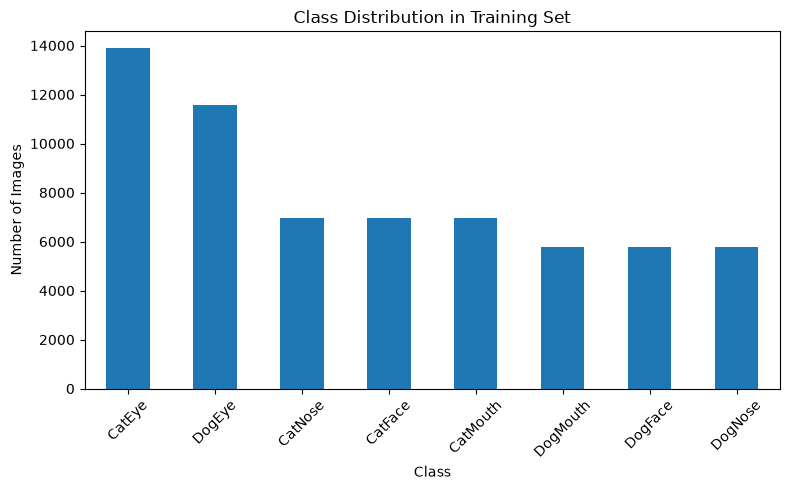

In [3]:
import matplotlib.pyplot as plt

class_counts.sort_values(ascending=False).plot(kind='bar', figsize=(8,5))
plt.title("Class Distribution in Training Set")
plt.ylabel("Number of Images")
plt.xlabel("Class")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

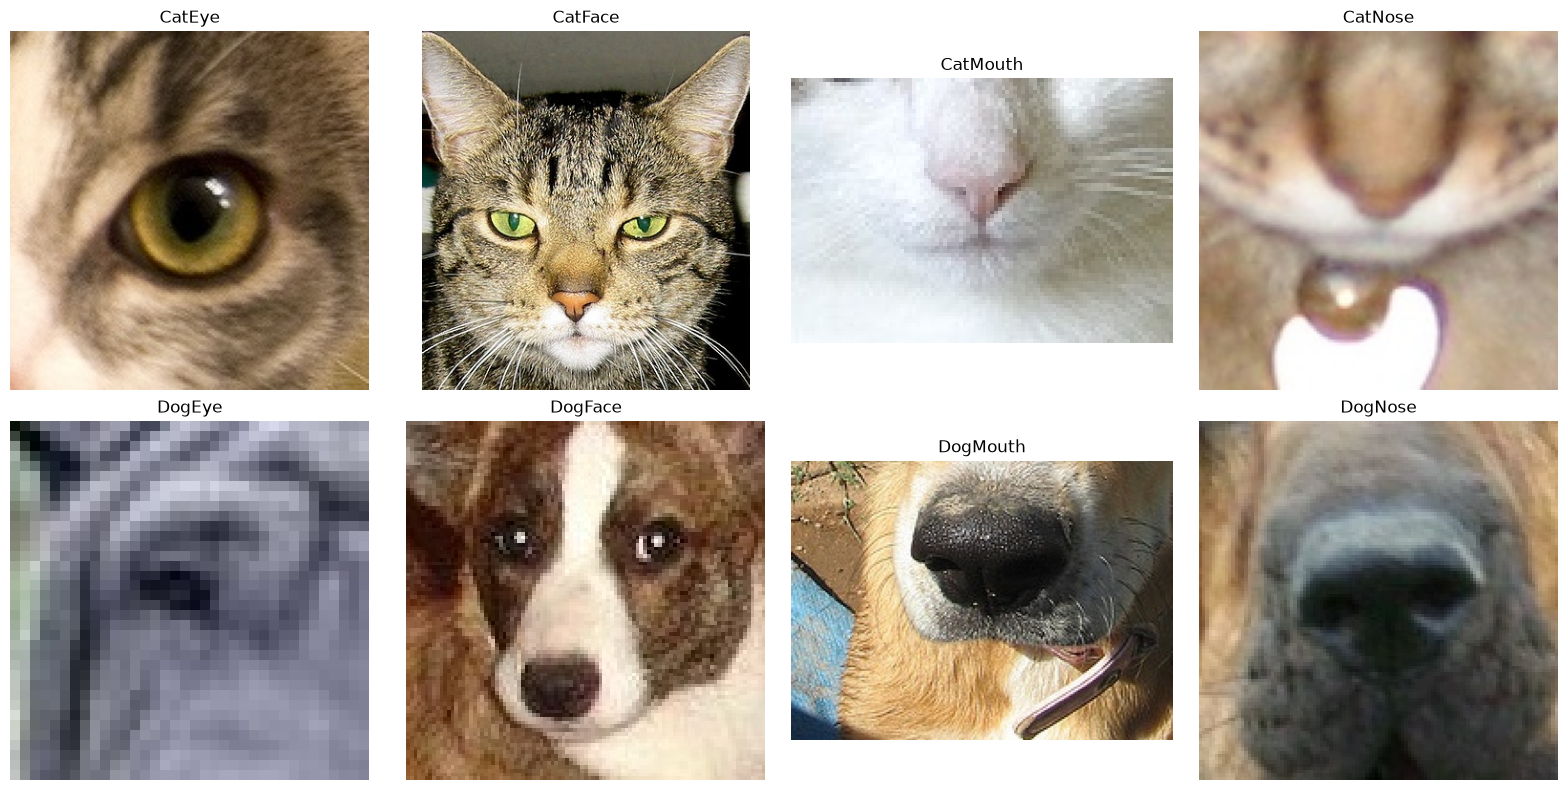

In [4]:
import os
from PIL import Image

img_dir = "../data/train/train"

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
classes = sorted(labels['class'].unique())

for ax, cls in zip(axes.flat, classes):
    sample_id = labels[labels['class'] == cls].iloc[0]['image_id']
    filename = f"{sample_id:05d}.jpg"
    img = Image.open(os.path.join(img_dir, filename))
    ax.imshow(img)
    ax.set_title(cls)
    ax.axis('off')

plt.tight_layout()
plt.show()

In [6]:
import random

sample_files = random.sample(os.listdir(img_dir), 200)
sizes = []
for f in sample_files:
    with Image.open(os.path.join(img_dir, f)) as im:
        sizes.append(im.size)

widths, heights = zip(*sizes)
print("Width  - min:", min(widths), "max:", max(widths), "mean:", sum(widths)/len(widths))
print("Height - min:", min(heights), "max:", max(heights), "mean:", sum(heights)/len(heights))

Width  - min: 16 max: 816 mean: 120.64
Height - min: 16 max: 796 mean: 120.05


48 / 200 sampled images have a dimension under 50px (24.0%)


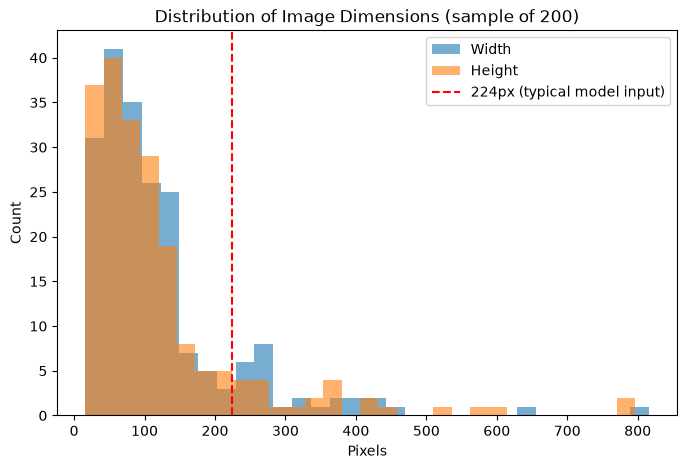

In [7]:
small_count = sum(1 for w, h in sizes if w < 50 or h < 50)
print(f"{small_count} / {len(sizes)} sampled images have a dimension under 50px ({small_count/len(sizes)*100:.1f}%)")

plt.figure(figsize=(8,5))
plt.hist(widths, bins=30, alpha=0.6, label='Width')
plt.hist(heights, bins=30, alpha=0.6, label='Height')
plt.axvline(224, color='red', linestyle='--', label='224px (typical model input)')
plt.title("Distribution of Image Dimensions (sample of 200)")
plt.xlabel("Pixels")
plt.ylabel("Count")
plt.legend()
plt.show()

In [8]:
labels['width'] = None
labels['height'] = None

sample_per_class = labels.groupby('class').sample(n=100, random_state=42)

dims = []
for _, row in sample_per_class.iterrows():
    filename = f"{row['image_id']:05d}.jpg"
    with Image.open(os.path.join(img_dir, filename)) as im:
        dims.append({'class': row['class'], 'width': im.size[0], 'height': im.size[1]})

dims_df = pd.DataFrame(dims)
dims_df.groupby('class')[['width', 'height']].mean().sort_values('width', ascending=False)

,width,height
class,,
DogFace,206.51,206.01
CatFace,203.50,241.25
CatMouth,126.74,88.28
DogMouth,125.57,92.88
CatEye,86.12,86.12
DogEye,80.68,80.68
CatNose,80.58,80.07
DogNose,71.54,71.54


In [9]:
corrupted = []
for f in os.listdir(img_dir):
    try:
        with Image.open(os.path.join(img_dir, f)) as im:
            im.verify()
    except Exception as e:
        corrupted.append((f, str(e)))

print(f"{len(corrupted)} corrupted/unreadable images out of {len(os.listdir(img_dir))}")
corrupted[:10]

0 corrupted/unreadable images out of 63660


[]

In [10]:
test_dir = "../data/test/test"
corrupted_test = []
for f in os.listdir(test_dir):
    try:
        with Image.open(os.path.join(test_dir, f)) as im:
            im.verify()
    except Exception as e:
        corrupted_test.append((f, str(e)))

print(f"{len(corrupted_test)} corrupted/unreadable images out of {len(os.listdir(test_dir))}")
corrupted_test[:10]

0 corrupted/unreadable images out of 29443


[]